In [1]:

import os

print("Files in current directory:")
print(os.listdir('/content'))



Files in current directory:
['.config', 'Advertising.csv', 'sample_data']


In [2]:

# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Ignore warnings
warnings.filterwarnings('ignore')

# Visualization style
sns.set_style("whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

# Load dataset

df = pd.read_csv('/content/Advertising.csv')

# Display first five rows
df.head()


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


### Observation
The Advertising dataset was successfully loaded using Pandas. It contains advertising expenditure information for TV, Radio and Newspaper along with the corresponding Sales values. These features will be used to analyse the relationship between advertising expenditure and product sales.

In [4]:

# Display dataset dimensions

print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()


Dataset Shape: (200, 5)

Column Names:
['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


### Observation
The dataset contains approximately 200 records and four main numerical columns: TV, Radio, Newspaper and Sales. The dataset contains information about advertising investments across different channels and their corresponding sales performance.

In [5]:

# Check missing values

print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Missing Values:
Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64

Duplicate Rows:
0


### Observation
The dataset was checked for missing values and duplicate records. The classic Advertising dataset contains no missing values or duplicate records. Therefore, the dataset is suitable for further analysis without requiring major corrections.

In [6]:

# Remove unnecessary index column if present

if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# Remove duplicate records
df = df.drop_duplicates()

# Handle missing values if present
df = df.dropna()

print("Data cleaning completed!")
print("Updated Dataset Shape:", df.shape)

df.head()


Data cleaning completed!
Updated Dataset Shape: (200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


### Observation
Data cleaning was performed by removing unnecessary columns, duplicate records and rows containing missing values. This process helps maintain data quality and prepares the dataset for accurate exploratory data analysis and model development.

In [7]:

# Generate descriptive statistics

df.describe()


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


### Observation
Descriptive statistics were generated to understand the distribution of advertising expenditure and sales. Measures such as mean, standard deviation, minimum and maximum values provide an overview of the dataset and help identify variations in advertising investments and sales performance.

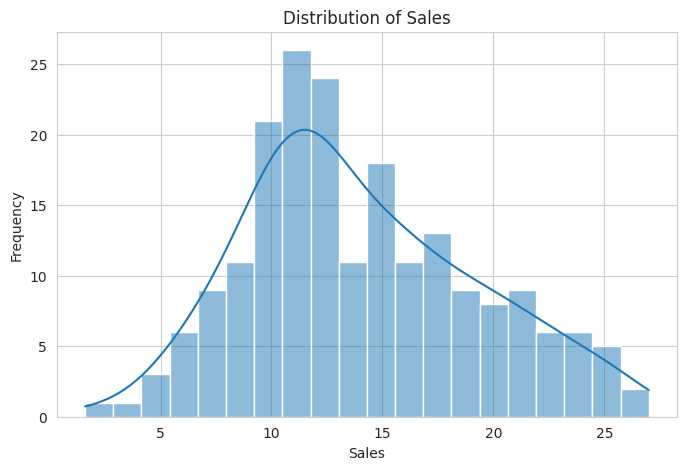

In [8]:

plt.figure(figsize=(8, 5))

sns.histplot(df['Sales'], bins=20, kde=True)

plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')

plt.show()


### Observation
The sales distribution histogram helps understand the frequency of different sales values. It provides an overview of how sales are distributed across the dataset and whether the values are concentrated within a particular range.

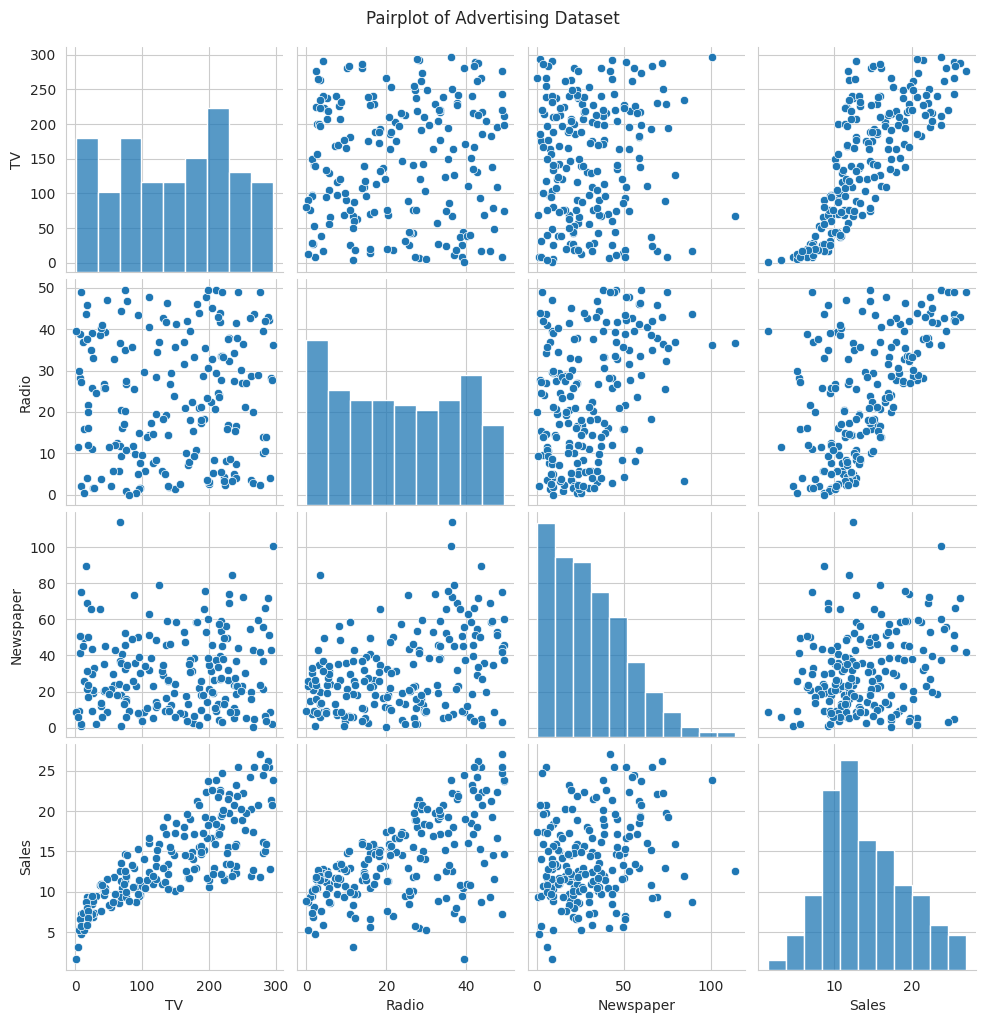

In [9]:

# Pairplot of all numerical features

sns.pairplot(df)

plt.suptitle('Pairplot of Advertising Dataset', y=1.02)

plt.show()


### Observation
The pairplot provides a visual representation of relationships between all numerical variables. It helps identify patterns, trends and possible correlations between advertising expenditure and sales. TV and Radio advertising appear to show positive relationships with Sales, while the Newspaper relationship appears comparatively weaker in the classic dataset.

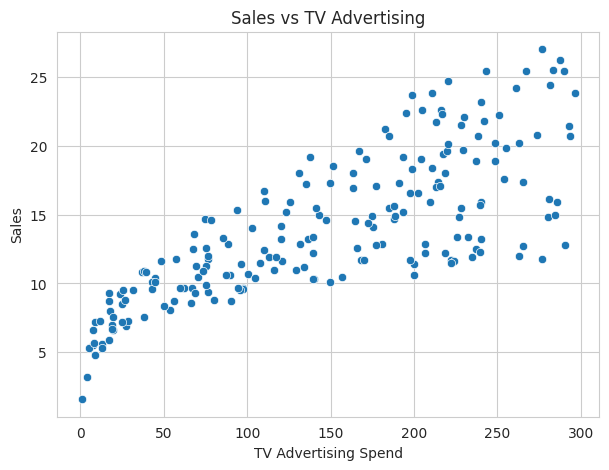

In [10]:

plt.figure(figsize=(7, 5))

sns.scatterplot(data=df, x='TV', y='Sales')

plt.title('Sales vs TV Advertising')
plt.xlabel('TV Advertising Spend')
plt.ylabel('Sales')

plt.show()


### Observation
The scatter plots help examine the relationship between each advertising channel and Sales individually.

- TV advertising shows a positive linear relationship with Sales.
- Radio advertising also shows a positive relationship with Sales.
- Newspaper advertising shows a comparatively weaker relationship with Sales.

These visual patterns help understand how different advertising channels are associated with product sales.

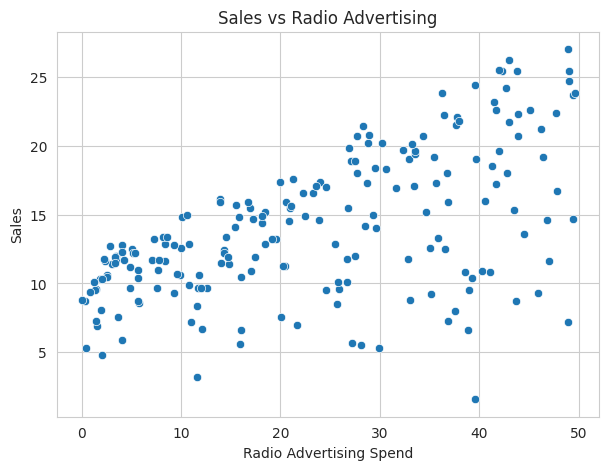

In [11]:

plt.figure(figsize=(7, 5))

sns.scatterplot(data=df, x='Radio', y='Sales')

plt.title('Sales vs Radio Advertising')
plt.xlabel('Radio Advertising Spend')
plt.ylabel('Sales')

plt.show()


### Observation
The correlation heatmap displays the strength and direction of linear relationships between the dataset variables. TV and Radio advertising generally show stronger positive correlations with Sales than Newspaper advertising. This suggests that TV and Radio expenditure may be more useful predictors of sales in this dataset.

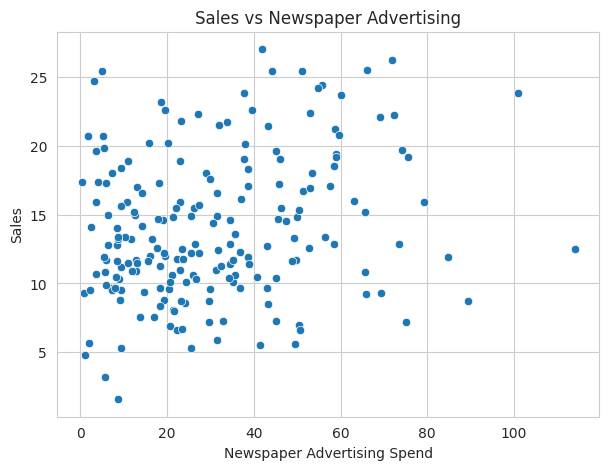

In [12]:

plt.figure(figsize=(7, 5))

sns.scatterplot(data=df, x='Newspaper', y='Sales')

plt.title('Sales vs Newspaper Advertising')
plt.xlabel('Newspaper Advertising Spend')
plt.ylabel('Sales')

plt.show()


### Observation
The independent variables (X) were defined as TV, Radio and Newspaper advertising expenditure. Sales was selected as the dependent variable (y). The objective is to train machine learning models that can predict Sales based on advertising expenditure.

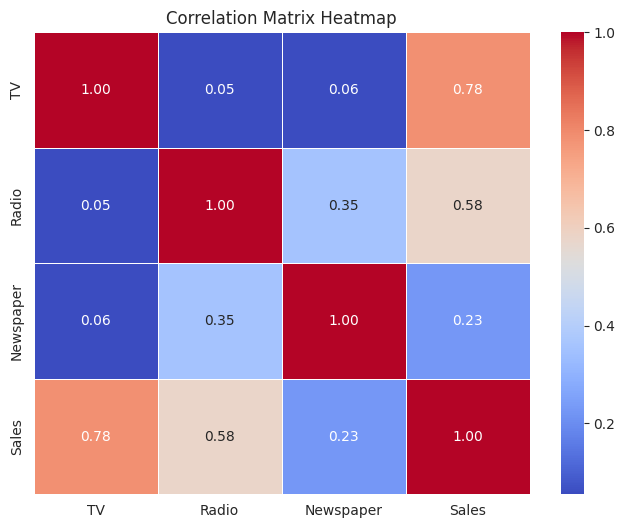

In [13]:

# Calculate correlation matrix

correlation = df.corr()

# Plot heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix Heatmap')

plt.show()


In [14]:

# Independent variables (features)

X = df[['TV', 'Radio', 'Newspaper']]

# Dependent variable (target)

y = df['Sales']

print("Independent Variables:")
print(X.head())

print("\nDependent Variable:")
print(y.head())


Independent Variables:
      TV  Radio  Newspaper
0  230.1   37.8       69.2
1   44.5   39.3       45.1
2   17.2   45.9       69.3
3  151.5   41.3       58.5
4  180.8   10.8       58.4

Dependent Variable:
0    22.1
1    10.4
2     9.3
3    18.5
4    12.9
Name: Sales, dtype: float64


In [15]:

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


Training Data Shape: (160, 3)
Testing Data Shape: (40, 3)


In [16]:

# Create Linear Regression model

lr_model = LinearRegression()

# Train the model

lr_model.fit(X_train, y_train)

# Predict sales

lr_predictions = lr_model.predict(X_test)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [17]:

# Create Random Forest Regressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model

rf_model.fit(X_train, y_train)

# Predict sales

rf_predictions = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")


Random Forest Model Trained Successfully!


In [18]:

# Function to evaluate regression models

def evaluate_model(y_true, y_pred, model_name):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    r2 = r2_score(y_true, y_pred)

    return {
        'Model': model_name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    }


# Evaluate Linear Regression

lr_results = evaluate_model(
    y_test,
    lr_predictions,
    'Linear Regression'
)

# Evaluate Random Forest

rf_results = evaluate_model(
    y_test,
    rf_predictions,
    'Random Forest'
)

# Compare results

results = pd.DataFrame([lr_results, rf_results])

print(results)


               Model       MAE      RMSE  R2 Score
0  Linear Regression  1.460757  1.781600  0.899438
1      Random Forest  0.620100  0.768591  0.981284


In [19]:

# Select best model based on RMSE

best_model_name = results.loc[
    results['RMSE'].idxmin(), 'Model'
]

if best_model_name == 'Linear Regression':
    best_model = lr_model
    best_predictions = lr_predictions
else:
    best_model = rf_model
    best_predictions = rf_predictions

print("Best Model:", best_model_name)


Best Model: Random Forest


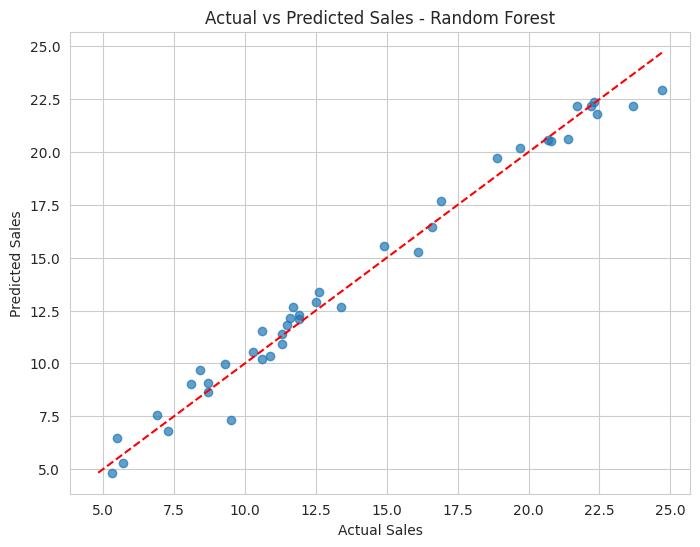

In [20]:

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.7
)

# Perfect prediction reference line

minimum = min(y_test.min(), best_predictions.min())
maximum = max(y_test.max(), best_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--'
)

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')

plt.title(f'Actual vs Predicted Sales - {best_model_name}')

plt.show()


### Observation
The actual vs predicted sales plot compares the model's predictions with the actual sales values. Points closer to the diagonal reference line indicate more accurate predictions. This visualization helps assess how well the selected model performs.

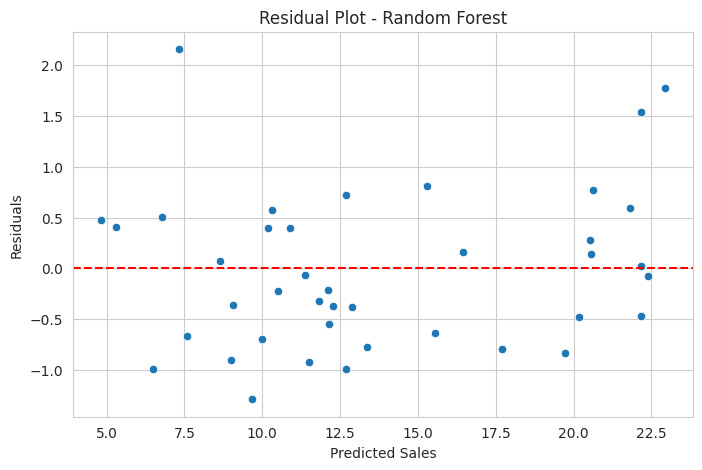

In [21]:

# Calculate residuals

residuals = y_test - best_predictions

# Create residual plot

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=best_predictions,
    y=residuals
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel('Predicted Sales')
plt.ylabel('Residuals')

plt.title(f'Residual Plot - {best_model_name}')

plt.show()


### Observation
The residual plot shows the differences between actual and predicted sales values. Randomly distributed residuals around the zero line generally indicate a reasonable model fit. Visible patterns or systematic deviations may suggest that the model has not captured certain relationships in the data.

In [22]:

# Display Linear Regression coefficients

coefficients = pd.DataFrame({
    'Advertising Channel': X.columns,
    'Coefficient': lr_model.coef_
})

print(coefficients.sort_values(
    by='Coefficient',
    ascending=False
))


  Advertising Channel  Coefficient
1               Radio     0.189195
0                  TV     0.044730
2           Newspaper     0.002761


  Advertising Channel  Importance
0                  TV    0.624810
1               Radio    0.362201
2           Newspaper    0.012989


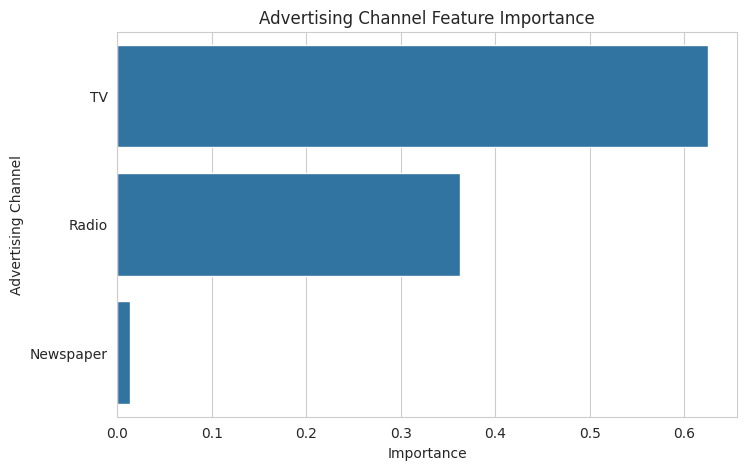

In [23]:

# Extract feature importance

importance = pd.DataFrame({
    'Advertising Channel': X.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

# Visualize feature importance

plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance,
    x='Importance',
    y='Advertising Channel'
)

plt.title('Advertising Channel Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Advertising Channel')

plt.show()


In [24]:

print("FINAL MODEL PERFORMANCE")
print("========================")

display(
    results.sort_values(by='RMSE')
)

print("\nBest Performing Model:", best_model_name)

print(
    "Best Model R2 Score:",
    round(
        r2_score(y_test, best_predictions),
        4
    )
)


FINAL MODEL PERFORMANCE


,Model,MAE,RMSE,R2 Score
1,Random Forest,0.620100,0.768591,0.981284
0,Linear Regression,1.460757,1.781600,0.899438



Best Performing Model: Random Forest
Best Model R2 Score: 0.9813



# Conclusion

In this project, Sales Prediction was performed using
Python and Machine Learning techniques.

The Advertising dataset was analysed using Pandas,
NumPy, Matplotlib and Seaborn.

Exploratory Data Analysis was performed to understand
the relationship between advertising expenditure
and product sales.

Linear Regression and Random Forest Regression
models were trained and evaluated using MAE, RMSE
and R2 Score.

The best-performing model was selected based on
RMSE.

Feature importance analysis was used to identify
the advertising channel with the highest predictive
contribution to sales.

This project demonstrates how machine learning
can be applied to analyse advertising data and
predict product sales.
